In [1]:
# Cell 1: Ridge Regression — Imports and Project Setup

import json
import time
import platform
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from pathlib import Path
from scipy.stats import pearsonr

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error,
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 3. Project paths
# ------------------------------------------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Solar_Wind_Project"
)

ML_PATH = PROJECT_PATH / "ML"

FLAT_DATA_PATH = ML_PATH / "data_flat"
ENGINEERED_DATA_PATH = ML_PATH / "data_engineered"

LINEAR_PATH = ML_PATH / "Linear"
RIDGE_PATH = LINEAR_PATH / "Ridge"

RESULTS_PATH = RIDGE_PATH
FIGURES_PATH = RIDGE_PATH / "figures"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. Model configuration
# ------------------------------------------------------------

MODEL_NAME = "Ridge"
RESULT_PREFIX = "ridge"

ALPHA_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]

# Match the common classical-model benchmark protocol.
WARMUP_RUNS = 2
INFERENCE_REPEATS = 10

FIGURE_DPI = 300

# ------------------------------------------------------------
# 5. Verify paths and environment
# ------------------------------------------------------------

print("Ridge Regression setup completed.")
print(f"Project path:      {PROJECT_PATH}")
print(f"Flat data path:    {FLAT_DATA_PATH}")
print(f"Engineered path:   {ENGINEERED_DATA_PATH}")
print(f"Ridge folder:      {RIDGE_PATH}")
print(f"Figures folder:    {FIGURES_PATH}")

print(f"\nRandom state:      {RANDOM_STATE}")
print(f"Alpha grid:        {ALPHA_GRID}")
print(f"Warm-up runs:      {WARMUP_RUNS}")
print(f"Timed repetitions: {INFERENCE_REPEATS}")
print(f"Scikit-learn:      {sklearn.__version__}")

assert FLAT_DATA_PATH.exists(), (
    f"Flat dataset directory not found: {FLAT_DATA_PATH}"
)

assert ENGINEERED_DATA_PATH.exists(), (
    f"Engineered dataset directory not found: "
    f"{ENGINEERED_DATA_PATH}"
)

print("\nDataset directories verified successfully.")
print("Cell 1 completed successfully.")

Mounted at /content/drive
Ridge Regression setup completed.
Project path:      /content/drive/MyDrive/Solar_Wind_Project
Flat data path:    /content/drive/MyDrive/Solar_Wind_Project/ML/data_flat
Engineered path:   /content/drive/MyDrive/Solar_Wind_Project/ML/data_engineered
Ridge folder:      /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge
Figures folder:    /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures

Random state:      42
Alpha grid:        [0.01, 0.1, 1.0, 10.0, 100.0]
Warm-up runs:      2
Timed repetitions: 10
Scikit-learn:      1.6.1

Dataset directories verified successfully.
Cell 1 completed successfully.


In [2]:
# Cell 2: Load and Verify Data

# ------------------------------------------------------------
# Load FLAT representation
# ------------------------------------------------------------

X_train_flat = np.load(FLAT_DATA_PATH / "X_train.npy").astype(
    np.float32, copy=False
)
X_val_flat = np.load(FLAT_DATA_PATH / "X_val.npy").astype(
    np.float32, copy=False
)
X_test_flat = np.load(FLAT_DATA_PATH / "X_test.npy").astype(
    np.float32, copy=False
)

y_train_flat = np.load(FLAT_DATA_PATH / "y_train.npy").reshape(-1).astype(
    np.float32, copy=False
)
y_val_flat = np.load(FLAT_DATA_PATH / "y_val.npy").reshape(-1).astype(
    np.float32, copy=False
)
y_test_flat = np.load(FLAT_DATA_PATH / "y_test.npy").reshape(-1).astype(
    np.float32, copy=False
)

# ------------------------------------------------------------
# Load ENGINEERED representation
# ------------------------------------------------------------

X_train_eng = np.load(
    ENGINEERED_DATA_PATH / "X_train.npy"
).astype(np.float32, copy=False)

X_val_eng = np.load(
    ENGINEERED_DATA_PATH / "X_val.npy"
).astype(np.float32, copy=False)

X_test_eng = np.load(
    ENGINEERED_DATA_PATH / "X_test.npy"
).astype(np.float32, copy=False)

y_train_eng = np.load(
    ENGINEERED_DATA_PATH / "y_train.npy"
).reshape(-1).astype(np.float32, copy=False)

y_val_eng = np.load(
    ENGINEERED_DATA_PATH / "y_val.npy"
).reshape(-1).astype(np.float32, copy=False)

y_test_eng = np.load(
    ENGINEERED_DATA_PATH / "y_test.npy"
).reshape(-1).astype(np.float32, copy=False)

# ------------------------------------------------------------
# Verify expected feature dimensions and split sizes
# ------------------------------------------------------------

expected_flat_shapes = {
    "train": (97897, 1008),
    "val": (20978, 1008),
    "test": (20979, 1008),
}

expected_eng_shapes = {
    "train": (97897, 112),
    "val": (20978, 112),
    "test": (20979, 112),
}

assert X_train_flat.shape == expected_flat_shapes["train"]
assert X_val_flat.shape == expected_flat_shapes["val"]
assert X_test_flat.shape == expected_flat_shapes["test"]

assert X_train_eng.shape == expected_eng_shapes["train"]
assert X_val_eng.shape == expected_eng_shapes["val"]
assert X_test_eng.shape == expected_eng_shapes["test"]

# ------------------------------------------------------------
# Verify target dimensions
# ------------------------------------------------------------

assert y_train_flat.shape == (97897,)
assert y_val_flat.shape == (20978,)
assert y_test_flat.shape == (20979,)

assert y_train_eng.shape == (97897,)
assert y_val_eng.shape == (20978,)
assert y_test_eng.shape == (20979,)

# ------------------------------------------------------------
# Verify target alignment between representations
# ------------------------------------------------------------

np.testing.assert_array_equal(y_train_flat, y_train_eng)
np.testing.assert_array_equal(y_val_flat, y_val_eng)
np.testing.assert_array_equal(y_test_flat, y_test_eng)

# ------------------------------------------------------------
# Verify all input and target arrays contain finite values
# ------------------------------------------------------------

arrays_to_check = {
    "X_train_flat": X_train_flat,
    "X_val_flat": X_val_flat,
    "X_test_flat": X_test_flat,
    "y_train_flat": y_train_flat,
    "y_val_flat": y_val_flat,
    "y_test_flat": y_test_flat,
    "X_train_eng": X_train_eng,
    "X_val_eng": X_val_eng,
    "X_test_eng": X_test_eng,
    "y_train_eng": y_train_eng,
    "y_val_eng": y_val_eng,
    "y_test_eng": y_test_eng,
}

for name, array in arrays_to_check.items():
    assert np.isfinite(array).all(), (
        f"Non-finite values found in {name}"
    )

# ------------------------------------------------------------
# Verification summary
# ------------------------------------------------------------

print("DATA VERIFICATION PASSED")

print("\nFLAT REPRESENTATION")
print("Train      :", X_train_flat.shape, y_train_flat.shape)
print("Validation :", X_val_flat.shape, y_val_flat.shape)
print("Test       :", X_test_flat.shape, y_test_flat.shape)

print("\nENGINEERED REPRESENTATION")
print("Train      :", X_train_eng.shape, y_train_eng.shape)
print("Validation :", X_val_eng.shape, y_val_eng.shape)
print("Test       :", X_test_eng.shape, y_test_eng.shape)

print("\nTarget arrays match between both representations.")
print("All arrays contain finite values.")
print("\nCell 2 completed successfully.")

DATA VERIFICATION PASSED

FLAT REPRESENTATION
Train      : (97897, 1008) (97897,)
Validation : (20978, 1008) (20978,)
Test       : (20979, 1008) (20979,)

ENGINEERED REPRESENTATION
Train      : (97897, 112) (97897,)
Validation : (20978, 112) (20978,)
Test       : (20979, 112) (20979,)

Target arrays match between both representations.
All arrays contain finite values.

Cell 2 completed successfully.


In [3]:
# Cell 3: Ridge Model Configuration

MODEL_NAME = "Ridge"

ALPHA_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]

# Inference benchmark configuration
WARMUP_RUNS = 2
INFERENCE_REPEATS = 10

ridge_config = {
    "model": MODEL_NAME,
    "alpha_grid": ALPHA_GRID,
    "fit_intercept": True,
    "solver": "auto",
    "random_state": RANDOM_STATE,
    "selection_metric": "validation_RMSE",
    "scaling": "StandardScaler fitted on training data only",
    "inference_warmup_runs": WARMUP_RUNS,
    "inference_timing_runs": INFERENCE_REPEATS,
    "feature_sets": {
        "flat": int(X_train_flat.shape[1]),
        "engineered": int(X_train_eng.shape[1]),
    },
}

# Save the configuration for reproducibility.
ridge_config_path = RESULTS_PATH / "ridge_configuration.json"

with open(ridge_config_path, "w") as f:
    json.dump(ridge_config, f, indent=4)

print("RIDGE MODEL CONFIGURATION")
print("-" * 55)

for key, value in ridge_config.items():
    print(f"{key}: {value}")

print(f"\nConfiguration saved to: {ridge_config_path}")
print("\nCell 3 completed successfully.")

RIDGE MODEL CONFIGURATION
-------------------------------------------------------
model: Ridge
alpha_grid: [0.01, 0.1, 1.0, 10.0, 100.0]
fit_intercept: True
solver: auto
random_state: 42
selection_metric: validation_RMSE
scaling: StandardScaler fitted on training data only
inference_warmup_runs: 2
inference_timing_runs: 10
feature_sets: {'flat': 1008, 'engineered': 112}

Configuration saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_configuration.json

Cell 3 completed successfully.


In [4]:
# Cell 4: Train Ridge — Flat Representation

print("TRAINING RIDGE — FLAT REPRESENTATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Scale features
# Fit the scaler on training data only.
# ------------------------------------------------------------

flat_scaler = StandardScaler()

print("\nFitting StandardScaler on flat training data...")

X_train_flat_scaled = flat_scaler.fit_transform(
    X_train_flat
).astype(np.float32, copy=False)

X_val_flat_scaled = flat_scaler.transform(
    X_val_flat
).astype(np.float32, copy=False)

X_test_flat_scaled = flat_scaler.transform(
    X_test_flat
).astype(np.float32, copy=False)

print("Scaling complete.")
print("Train      :", X_train_flat_scaled.shape)
print("Validation :", X_val_flat_scaled.shape)
print("Test       :", X_test_flat_scaled.shape)

# ------------------------------------------------------------
# 2. Select alpha using validation RMSE
# ------------------------------------------------------------

flat_validation_results = []

best_flat_alpha = None
best_flat_val_rmse = np.inf
best_flat_model = None
best_flat_train_time = None

flat_tuning_start = time.perf_counter()

print("\nSelecting alpha using VALIDATION RMSE...\n")

for alpha in ALPHA_GRID:
    model = Ridge(
        alpha=alpha,
        fit_intercept=True,
        solver="auto",
    )

    start_time = time.perf_counter()

    model.fit(
        X_train_flat_scaled,
        y_train_flat,
    )

    training_time = time.perf_counter() - start_time

    val_predictions = model.predict(X_val_flat_scaled)

    val_rmse = float(
        np.sqrt(
            mean_squared_error(
                y_val_flat,
                val_predictions,
            )
        )
    )

    flat_validation_results.append({
        "alpha": float(alpha),
        "validation_rmse": val_rmse,
        "training_time_seconds": float(training_time),
    })

    print(
        f"alpha={alpha:<7} | "
        f"Validation RMSE={val_rmse:.4f} nT | "
        f"Training time={training_time:.3f} s"
    )

    if val_rmse < best_flat_val_rmse:
        best_flat_val_rmse = val_rmse
        best_flat_alpha = alpha
        best_flat_model = model
        best_flat_train_time = training_time

flat_tuning_duration = time.perf_counter() - flat_tuning_start

# ------------------------------------------------------------
# 3. Store the selected flat model
# ------------------------------------------------------------

ridge_flat_model = best_flat_model
flat_training_duration = best_flat_train_time

flat_validation_predictions = ridge_flat_model.predict(
    X_val_flat_scaled
)

# ------------------------------------------------------------
# 4. Save the alpha search results
# ------------------------------------------------------------

flat_validation_results_df = pd.DataFrame(
    flat_validation_results
)

flat_search_path = RESULTS_PATH / "ridge_flat_alpha_search.csv"

flat_validation_results_df.to_csv(
    flat_search_path,
    index=False,
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BEST FLAT RIDGE MODEL")
print("=" * 65)

print("Selected alpha          :", best_flat_alpha)
print(f"Best validation RMSE    : {best_flat_val_rmse:.4f} nT")
print(f"Selected fit duration   : {flat_training_duration:.3f} s")
print(f"Total alpha search time : {flat_tuning_duration:.3f} s")
print(f"Coefficient count       : {ridge_flat_model.coef_.size}")

print(f"\nAlpha search results saved to: {flat_search_path}")
print("\nCell 4 completed successfully.")

TRAINING RIDGE — FLAT REPRESENTATION

Fitting StandardScaler on flat training data...
Scaling complete.
Train      : (97897, 1008)
Validation : (20978, 1008)
Test       : (20979, 1008)

Selecting alpha using VALIDATION RMSE...

alpha=0.01    | Validation RMSE=9.4950 nT | Training time=60.177 s
alpha=0.1     | Validation RMSE=9.4885 nT | Training time=45.498 s


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.44812e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


alpha=1.0     | Validation RMSE=9.4870 nT | Training time=2.969 s
alpha=10.0    | Validation RMSE=9.4840 nT | Training time=2.237 s
alpha=100.0   | Validation RMSE=9.4633 nT | Training time=2.785 s

BEST FLAT RIDGE MODEL
Selected alpha          : 100.0
Best validation RMSE    : 9.4633 nT
Selected fit duration   : 2.785 s
Total alpha search time : 113.862 s
Coefficient count       : 1008

Alpha search results saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_flat_alpha_search.csv

Cell 4 completed successfully.


In [5]:
# Cell 5: Train Ridge — Engineered Representation

print("TRAINING RIDGE — ENGINEERED REPRESENTATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Scale engineered features
# Fit the scaler on training data only.
# ------------------------------------------------------------

engineered_scaler = StandardScaler()

print("\nFitting StandardScaler on engineered training data...")

X_train_eng_scaled = engineered_scaler.fit_transform(
    X_train_eng
).astype(np.float32, copy=False)

X_val_eng_scaled = engineered_scaler.transform(
    X_val_eng
).astype(np.float32, copy=False)

X_test_eng_scaled = engineered_scaler.transform(
    X_test_eng
).astype(np.float32, copy=False)

print("Scaling complete.")
print("Train      :", X_train_eng_scaled.shape)
print("Validation :", X_val_eng_scaled.shape)
print("Test       :", X_test_eng_scaled.shape)

# ------------------------------------------------------------
# 2. Select alpha using validation RMSE
# ------------------------------------------------------------

engineered_validation_results = []

best_eng_alpha = None
best_eng_val_rmse = np.inf
best_eng_model = None
best_eng_train_time = None

engineered_tuning_start = time.perf_counter()

print("\nSelecting alpha using VALIDATION RMSE...\n")

for alpha in ALPHA_GRID:
    model = Ridge(
        alpha=alpha,
        fit_intercept=True,
        solver="auto",
    )

    start_time = time.perf_counter()

    model.fit(
        X_train_eng_scaled,
        y_train_eng,
    )

    training_time = time.perf_counter() - start_time

    val_predictions = model.predict(X_val_eng_scaled)

    val_rmse = float(
        np.sqrt(
            mean_squared_error(
                y_val_eng,
                val_predictions,
            )
        )
    )

    engineered_validation_results.append({
        "alpha": float(alpha),
        "validation_rmse": val_rmse,
        "training_time_seconds": float(training_time),
    })

    print(
        f"alpha={alpha:<7} | "
        f"Validation RMSE={val_rmse:.4f} nT | "
        f"Training time={training_time:.3f} s"
    )

    if val_rmse < best_eng_val_rmse:
        best_eng_val_rmse = val_rmse
        best_eng_alpha = alpha
        best_eng_model = model
        best_eng_train_time = training_time

engineered_tuning_duration = (
    time.perf_counter() - engineered_tuning_start
)

# ------------------------------------------------------------
# 3. Store the selected engineered model
# ------------------------------------------------------------

ridge_engineered_model = best_eng_model
engineered_training_duration = best_eng_train_time

engineered_validation_predictions = (
    ridge_engineered_model.predict(X_val_eng_scaled)
)

# ------------------------------------------------------------
# 4. Save alpha search results
# ------------------------------------------------------------

engineered_validation_results_df = pd.DataFrame(
    engineered_validation_results
)

engineered_search_path = (
    RESULTS_PATH / "ridge_engineered_alpha_search.csv"
)

engineered_validation_results_df.to_csv(
    engineered_search_path,
    index=False,
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BEST ENGINEERED RIDGE MODEL")
print("=" * 65)

print("Selected alpha          :", best_eng_alpha)
print(f"Best validation RMSE    : {best_eng_val_rmse:.4f} nT")
print(f"Selected fit duration   : {engineered_training_duration:.3f} s")
print(f"Total alpha search time : {engineered_tuning_duration:.3f} s")
print(f"Coefficient count       : {ridge_engineered_model.coef_.size}")

print(f"\nAlpha search results saved to: {engineered_search_path}")
print("\nCell 5 completed successfully.")

TRAINING RIDGE — ENGINEERED REPRESENTATION

Fitting StandardScaler on engineered training data...
Scaling complete.
Train      : (97897, 112)
Validation : (20978, 112)
Test       : (20979, 112)

Selecting alpha using VALIDATION RMSE...



/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.61462e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


alpha=0.01    | Validation RMSE=9.3642 nT | Training time=0.504 s


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=3.33015e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


alpha=0.1     | Validation RMSE=9.3411 nT | Training time=0.238 s
alpha=1.0     | Validation RMSE=9.3399 nT | Training time=0.245 s
alpha=10.0    | Validation RMSE=9.3408 nT | Training time=0.316 s
alpha=100.0   | Validation RMSE=9.3375 nT | Training time=1.222 s

BEST ENGINEERED RIDGE MODEL
Selected alpha          : 100.0
Best validation RMSE    : 9.3375 nT
Selected fit duration   : 1.222 s
Total alpha search time : 2.564 s
Coefficient count       : 112

Alpha search results saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_engineered_alpha_search.csv

Cell 5 completed successfully.


In [6]:
# Cell 6: Ridge Regression — Test Set Evaluation

print("RIDGE REGRESSION — TEST SET EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify target alignment
# ------------------------------------------------------------

np.testing.assert_array_equal(y_test_flat, y_test_eng)

# ------------------------------------------------------------
# 2. Generate held-out test predictions
# ------------------------------------------------------------

print("Generating flat-feature test predictions...")

flat_predictions = ridge_flat_model.predict(
    X_test_flat_scaled
)

print("Generating engineered-feature test predictions...")

engineered_predictions = ridge_engineered_model.predict(
    X_test_eng_scaled
)

# ------------------------------------------------------------
# 3. Common regression metric function
# Same seven metrics used in previous experiments.
# ------------------------------------------------------------

def evaluate_regression(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if len(y_true) != len(y_pred):
        raise ValueError(
            "Actual and predicted arrays have different lengths."
        )

    correlation = (
        float(pearsonr(y_true, y_pred).statistic)
        if np.std(y_true) > 0 and np.std(y_pred) > 0
        else float("nan")
    )

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_Correlation": correlation,
        "Median_Absolute_Error": float(
            median_absolute_error(y_true, y_pred)
        ),
        "Explained_Variance": float(
            explained_variance_score(y_true, y_pred)
        ),
        "Maximum_Absolute_Error": float(
            max_error(y_true, y_pred)
        ),
    }


# ------------------------------------------------------------
# 4. Evaluate both representations
# ------------------------------------------------------------

flat_metrics = evaluate_regression(
    y_test_flat,
    flat_predictions,
)

engineered_metrics = evaluate_regression(
    y_test_eng,
    engineered_predictions,
)

# ------------------------------------------------------------
# 5. Display test metrics
# ------------------------------------------------------------

ridge_test_metrics_df = pd.DataFrame([
    {
        "Representation": "Flat",
        **flat_metrics,
    },
    {
        "Representation": "Engineered",
        **engineered_metrics,
    },
])

print("\nRIDGE HELD-OUT TEST METRICS")
display(ridge_test_metrics_df.round(4))

print("\nSelected hyperparameters:")
print(f"Flat alpha       : {best_flat_alpha}")
print(f"Engineered alpha : {best_eng_alpha}")

# ------------------------------------------------------------
# 6. Save test metrics
# ------------------------------------------------------------

ridge_metrics_csv_path = (
    RESULTS_PATH / "ridge_test_metrics.csv"
)

ridge_metrics_json_path = (
    RESULTS_PATH / "ridge_test_metrics.json"
)

ridge_test_metrics_df.to_csv(
    ridge_metrics_csv_path,
    index=False,
)

with open(ridge_metrics_json_path, "w") as f:
    json.dump(
        {
            "flat": flat_metrics,
            "engineered": engineered_metrics,
        },
        f,
        indent=4,
        allow_nan=True,
    )

# ------------------------------------------------------------
# 7. Save test predictions
# ------------------------------------------------------------

np.save(
    RESULTS_PATH / "ridge_flat_test_predictions.npy",
    flat_predictions,
)

np.save(
    RESULTS_PATH / "ridge_engineered_test_predictions.npy",
    engineered_predictions,
)

ridge_predictions_df = pd.DataFrame({
    "actual_dst": y_test_flat,
    "flat_predicted_dst": flat_predictions,
    "engineered_predicted_dst": engineered_predictions,
})

ridge_predictions_csv_path = (
    RESULTS_PATH / "ridge_test_predictions.csv"
)

ridge_predictions_df.to_csv(
    ridge_predictions_csv_path,
    index=False,
)

print("\nSaved files:")
print(f"Test metrics CSV  : {ridge_metrics_csv_path}")
print(f"Test metrics JSON : {ridge_metrics_json_path}")
print(f"Test predictions  : {ridge_predictions_csv_path}")

print("\nCell 6 completed successfully.")

RIDGE REGRESSION — TEST SET EVALUATION
Generating flat-feature test predictions...
Generating engineered-feature test predictions...

RIDGE HELD-OUT TEST METRICS


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,6.1204,8.0877,0.4359,0.7209,4.9007,0.4433,71.3566
1,Engineered,6.0419,8.0020,0.4478,0.7236,4.8117,0.4510,76.0670



Selected hyperparameters:
Flat alpha       : 100.0
Engineered alpha : 100.0

Saved files:
Test metrics CSV  : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_test_metrics.csv
Test metrics JSON : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_test_metrics.json
Test predictions  : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_test_predictions.csv

Cell 6 completed successfully.


In [7]:
# Cell 7: Ridge — Inference Latency and Throughput

def measure_inference_performance(
    model,
    X_test,
    n_warmup=WARMUP_RUNS,
    n_runs=INFERENCE_REPEATS,
):
    # Warm-up predictions; excluded from timing statistics.
    for _ in range(n_warmup):
        _ = model.predict(X_test)

    timings = []

    # Timed inference repetitions.
    for repeat in range(n_runs):
        start_time = time.perf_counter()
        _ = model.predict(X_test)
        elapsed = time.perf_counter() - start_time

        timings.append(float(elapsed))

        print(
            f"Repeat {repeat + 1}/{n_runs}: "
            f"{elapsed:.6f} seconds"
        )

    mean_time = float(np.mean(timings))
    std_time = float(np.std(timings, ddof=0))
    n_samples = len(X_test)

    return {
        "warmup_runs": int(n_warmup),
        "timed_repeats": int(n_runs),
        "test_samples": int(n_samples),
        "mean_inference_time_seconds": mean_time,
        "std_inference_time_seconds": std_time,
        "latency_ms_per_sample": float(
            mean_time / n_samples * 1000
        ),
        "throughput_samples_per_second": float(
            n_samples / mean_time
        ),
        "all_timings_seconds": timings,
    }


# ------------------------------------------------------------
# Benchmark flat Ridge
# ------------------------------------------------------------

print("Benchmarking Ridge — flat representation...")

flat_inference = measure_inference_performance(
    ridge_flat_model,
    X_test_flat_scaled,
)


# ------------------------------------------------------------
# Benchmark engineered Ridge
# ------------------------------------------------------------

print("\nBenchmarking Ridge — engineered representation...")

engineered_inference = measure_inference_performance(
    ridge_engineered_model,
    X_test_eng_scaled,
)


# ------------------------------------------------------------
# Display comparable benchmark metrics
# ------------------------------------------------------------

inference_results = {
    "flat": flat_inference,
    "engineered": engineered_inference,
}

inference_summary = pd.DataFrame([
    {
        "Representation": representation.title(),
        "Mean Inference Time (s)": result[
            "mean_inference_time_seconds"
        ],
        "Std. Deviation (s)": result[
            "std_inference_time_seconds"
        ],
        "Latency (ms/sample)": result[
            "latency_ms_per_sample"
        ],
        "Throughput (samples/s)": result[
            "throughput_samples_per_second"
        ],
    }
    for representation, result in inference_results.items()
])

print("\nRidge inference benchmark:")
display(inference_summary.round(6))


# ------------------------------------------------------------
# Save benchmark results
# ------------------------------------------------------------

inference_json_path = (
    RESULTS_PATH / "ridge_inference_timing.json"
)

inference_csv_path = (
    RESULTS_PATH / "ridge_inference_timing.csv"
)

with open(inference_json_path, "w") as f:
    json.dump(inference_results, f, indent=4)

inference_summary.to_csv(inference_csv_path, index=False)

print(f"\nSaved: {inference_json_path}")
print(f"Saved: {inference_csv_path}")

print("\nCell 7 completed successfully.")

Benchmarking Ridge — flat representation...
Repeat 1/10: 0.077233 seconds
Repeat 2/10: 0.057419 seconds
Repeat 3/10: 0.060916 seconds
Repeat 4/10: 0.043816 seconds
Repeat 5/10: 0.081510 seconds
Repeat 6/10: 0.090959 seconds
Repeat 7/10: 0.072785 seconds
Repeat 8/10: 0.076128 seconds
Repeat 9/10: 0.077719 seconds
Repeat 10/10: 0.060871 seconds

Benchmarking Ridge — engineered representation...
Repeat 1/10: 0.017066 seconds
Repeat 2/10: 0.012862 seconds
Repeat 3/10: 0.015931 seconds
Repeat 4/10: 0.018886 seconds
Repeat 5/10: 0.025938 seconds
Repeat 6/10: 0.009879 seconds
Repeat 7/10: 0.008841 seconds
Repeat 8/10: 0.011033 seconds
Repeat 9/10: 0.017057 seconds
Repeat 10/10: 0.021821 seconds

Ridge inference benchmark:


,Representation,Mean Inference Time (s),Std. Deviation (s),Latency (ms/sample),Throughput (samples/s)
0,Flat,0.069936,0.013186,0.003334,2.999764e+05
1,Engineered,0.015931,0.005162,0.000759,1.316829e+06



Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_inference_timing.json
Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_inference_timing.csv

Cell 7 completed successfully.


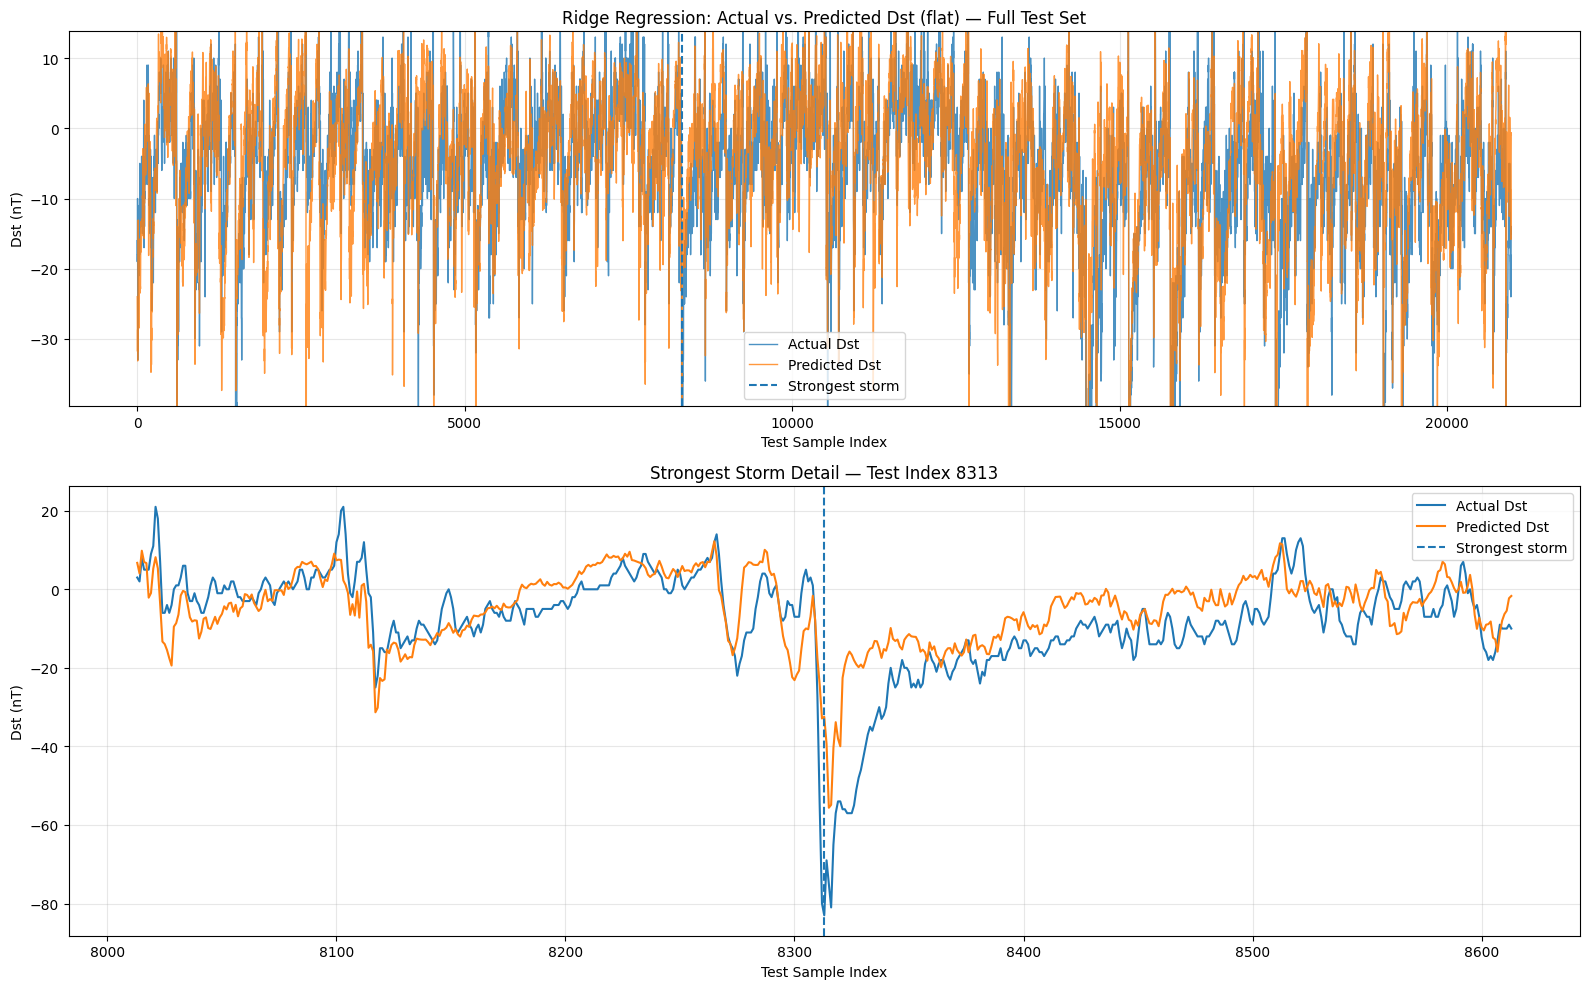

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_01_actual_vs_predicted_flat.png
Strongest storm test index: 8313
Actual Dst at strongest storm: -83.00 nT


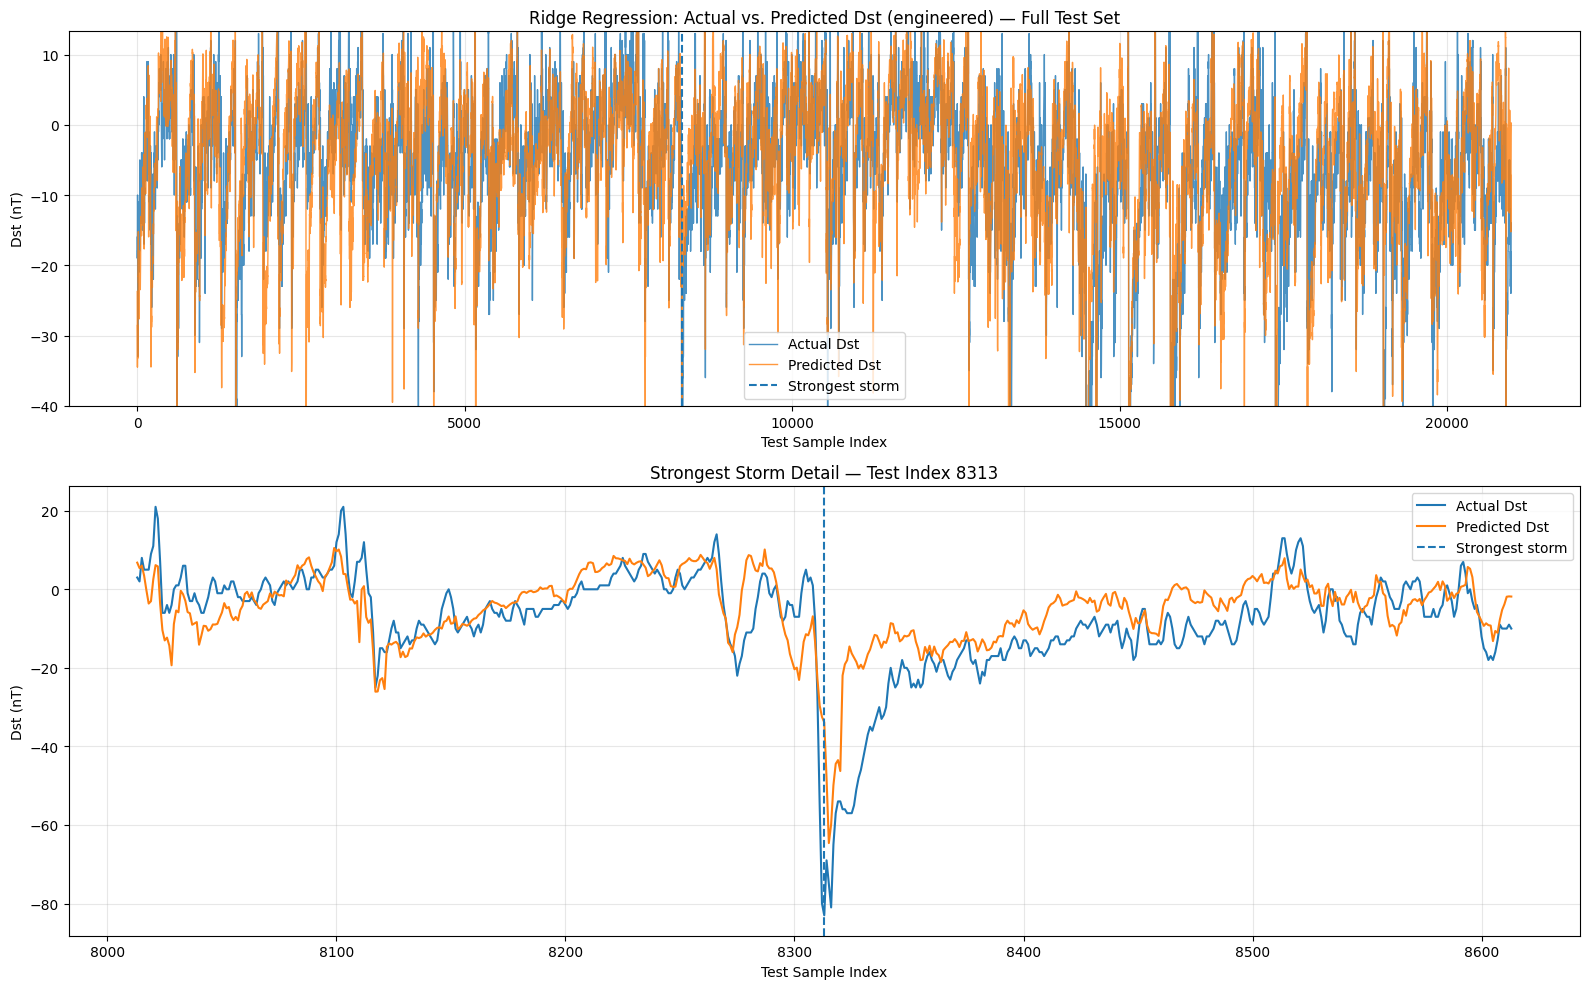

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_01_actual_vs_predicted_engineered.png
Strongest storm test index: 8313
Actual Dst at strongest storm: -83.00 nT

Cell 8 completed successfully.


In [8]:
# Cell 8: Ridge — Actual vs. Predicted Dst

def plot_actual_vs_predicted(y_true, y_pred, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    assert len(y_true) == len(y_pred), (
        "Actual and predicted arrays have different lengths."
    )

    # Locate the strongest storm from the actual test targets.
    storm_index = int(np.argmin(y_true))

    # Zoom around the strongest storm.
    window = 300
    start_index = max(0, storm_index - window)
    end_index = min(len(y_true), storm_index + window + 1)

    # Use central 98% of values for the overview plot limits.
    combined_values = np.concatenate([y_true, y_pred])
    lower_limit, upper_limit = np.percentile(
        combined_values, [1, 99]
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [1, 1.2]},
    )

    # --------------------------------------------------------
    # 1. Full test-set overview
    # --------------------------------------------------------
    axes[0].plot(
        y_true,
        label="Actual Dst",
        linewidth=1,
        alpha=0.8,
    )
    axes[0].plot(
        y_pred,
        label="Predicted Dst",
        linewidth=1,
        alpha=0.8,
    )
    axes[0].axvline(
        storm_index,
        linestyle="--",
        linewidth=1.5,
        label="Strongest storm",
    )

    axes[0].set_ylim(lower_limit, upper_limit)
    axes[0].set_title(
        f"Ridge Regression: Actual vs. Predicted Dst "
        f"({representation}) — Full Test Set"
    )
    axes[0].set_xlabel("Test Sample Index")
    axes[0].set_ylabel("Dst (nT)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # --------------------------------------------------------
    # 2. Zoomed strongest-storm interval
    # --------------------------------------------------------
    indices = np.arange(start_index, end_index)

    axes[1].plot(
        indices,
        y_true[start_index:end_index],
        label="Actual Dst",
        linewidth=1.5,
    )
    axes[1].plot(
        indices,
        y_pred[start_index:end_index],
        label="Predicted Dst",
        linewidth=1.5,
    )
    axes[1].axvline(
        storm_index,
        linestyle="--",
        linewidth=1.5,
        label="Strongest storm",
    )

    axes[1].set_title(
        f"Strongest Storm Detail — Test Index {storm_index}"
    )
    axes[1].set_xlabel("Test Sample Index")
    axes[1].set_ylabel("Dst (nT)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"ridge_01_actual_vs_predicted_{representation}.png"
    )

    fig.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")
    print(f"Strongest storm test index: {storm_index}")
    print(
        f"Actual Dst at strongest storm: "
        f"{y_true[storm_index]:.2f} nT"
    )


# Flat representation
plot_actual_vs_predicted(
    y_test_flat,
    flat_predictions,
    "flat",
)

# Engineered representation
plot_actual_vs_predicted(
    y_test_eng,
    engineered_predictions,
    "engineered",
)

print("\nCell 8 completed successfully.")

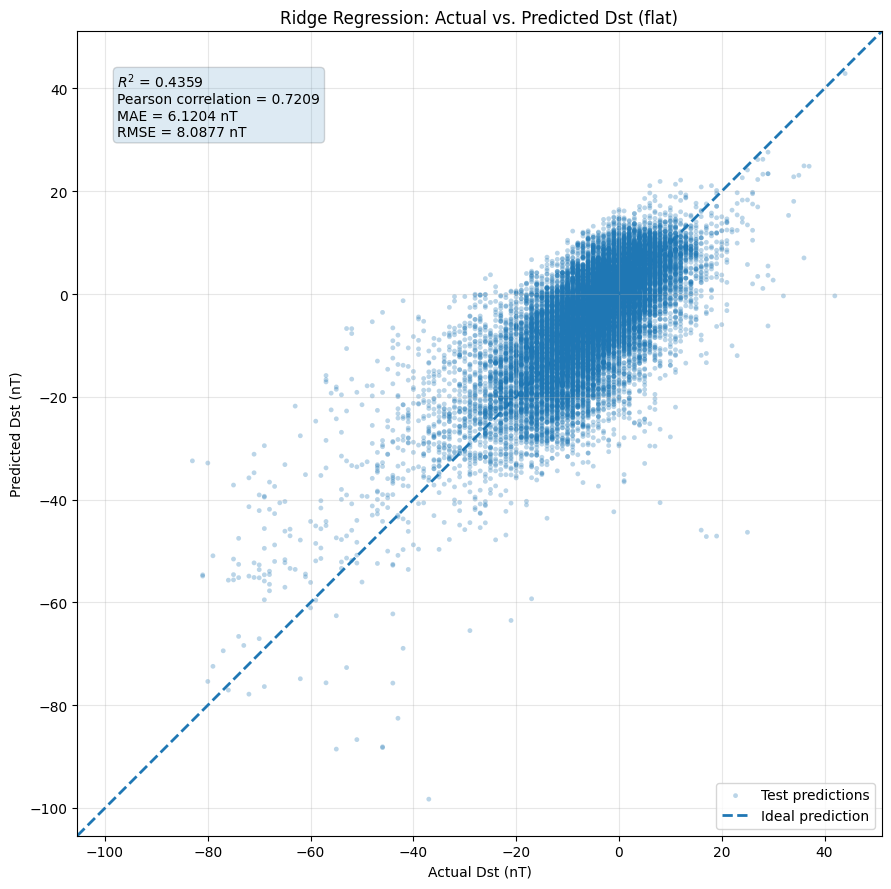

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_02_prediction_scatter_flat.png


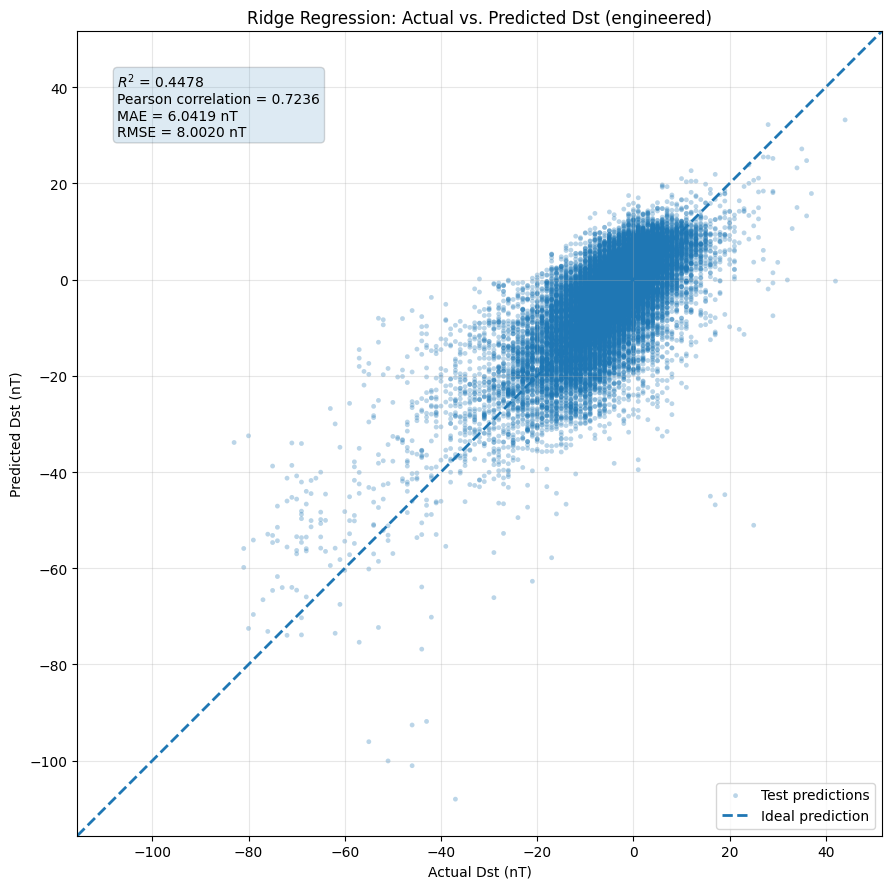

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_02_prediction_scatter_engineered.png

Cell 9 completed successfully.


In [9]:
# Cell 9: Ridge — Prediction Scatter Plots

def plot_prediction_scatter(y_true, y_pred, metrics, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    fig, ax = plt.subplots(figsize=(9, 9))

    ax.scatter(
        y_true,
        y_pred,
        s=12,
        alpha=0.3,
        edgecolors="none",
        label="Test predictions",
    )

    # Shared limits for the actual and predicted axes.
    lower = min(float(np.min(y_true)), float(np.min(y_pred)))
    upper = max(float(np.max(y_true)), float(np.max(y_pred)))
    padding = max((upper - lower) * 0.05, 2)

    axis_min = lower - padding
    axis_max = upper + padding

    # Ideal prediction line.
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        linestyle="--",
        linewidth=2,
        label="Ideal prediction",
    )

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"Ridge Regression: Actual vs. Predicted Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Predicted Dst (nT)")

    annotation = (
        f"$R^2$ = {metrics['R2']:.4f}\n"
        f"Pearson correlation = {metrics['Pearson_Correlation']:.4f}\n"
        f"MAE = {metrics['MAE']:.4f} nT\n"
        f"RMSE = {metrics['RMSE']:.4f} nT"
    )

    ax.text(
        0.05,
        0.95,
        annotation,
        transform=ax.transAxes,
        verticalalignment="top",
        bbox={"boxstyle": "round", "alpha": 0.15},
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"ridge_02_prediction_scatter_{representation}.png"
    )

    fig.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


# Flat representation
plot_prediction_scatter(
    y_test_flat,
    flat_predictions,
    flat_metrics,
    "flat",
)

# Engineered representation
plot_prediction_scatter(
    y_test_eng,
    engineered_predictions,
    engineered_metrics,
    "engineered",
)

print("\nCell 9 completed successfully.")

Flat representation — RMSE by Dst intensity:


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,22.6956
1,"(-60, -40]",188,21.2924
2,"(-40, -20]",1441,11.4129
3,"(-20, 0]",13681,7.3706
4,> 0,5596,7.5440



Engineered representation — RMSE by Dst intensity:


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,20.7697
1,"(-60, -40]",188,21.1883
2,"(-40, -20]",1441,11.2143
3,"(-20, 0]",13681,7.2506
4,> 0,5596,7.6440


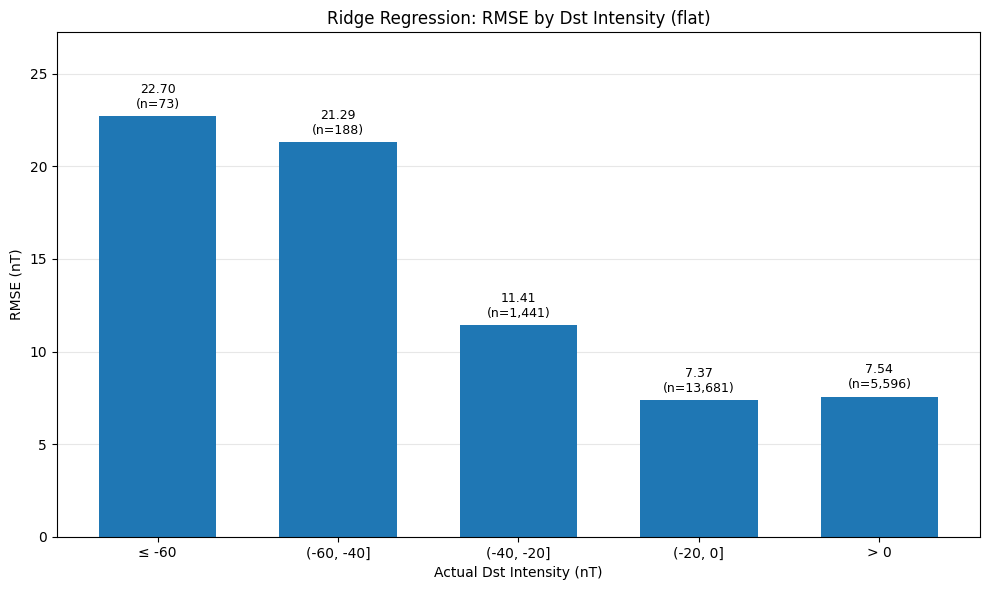

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_03_rmse_by_dst_intensity_flat.png


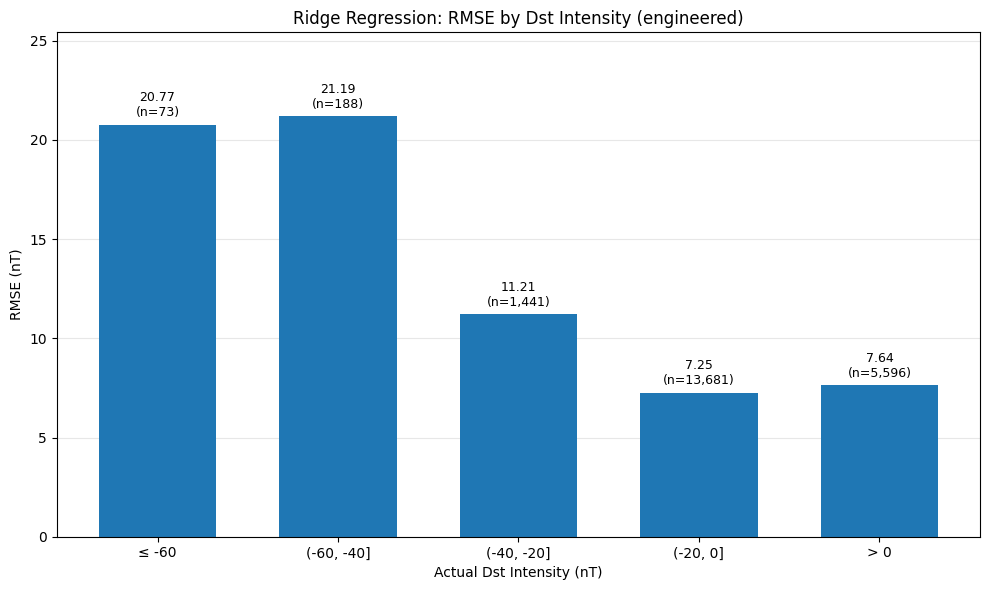

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_03_rmse_by_dst_intensity_engineered.png

Cell 10 completed successfully.


In [10]:
# Cell 10: Ridge — RMSE by Dst Intensity

DST_BINS = [
    ("≤ -60", lambda y: y <= -60),
    ("(-60, -40]", lambda y: (y > -60) & (y <= -40)),
    ("(-40, -20]", lambda y: (y > -40) & (y <= -20)),
    ("(-20, 0]", lambda y: (y > -20) & (y <= 0)),
    ("> 0", lambda y: y > 0),
]


def calculate_rmse_by_intensity(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    results = []

    for bin_name, condition in DST_BINS:
        mask = condition(y_true)
        sample_count = int(np.sum(mask))

        if sample_count > 0:
            rmse = float(
                np.sqrt(
                    mean_squared_error(
                        y_true[mask],
                        y_pred[mask],
                    )
                )
            )
        else:
            rmse = np.nan

        results.append({
            "dst_intensity_bin": bin_name,
            "sample_count": sample_count,
            "RMSE": rmse,
        })

    return pd.DataFrame(results)


def plot_rmse_by_intensity(results, representation):
    fig, ax = plt.subplots(figsize=(10, 6))

    labels = results["dst_intensity_bin"].tolist()
    values = results["RMSE"].to_numpy(dtype=float)
    counts = results["sample_count"].to_numpy(dtype=int)

    positions = np.arange(len(labels))
    valid = np.isfinite(values)

    bars = ax.bar(
        positions[valid],
        values[valid],
        width=0.65,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels)

    ax.set_title(
        f"Ridge Regression: RMSE by Dst Intensity ({representation})"
    )
    ax.set_xlabel("Actual Dst Intensity (nT)")
    ax.set_ylabel("RMSE (nT)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    if np.any(valid):
        ax.set_ylim(0, max(values[valid]) * 1.2)

    for bar, value, count in zip(
        bars,
        values[valid],
        counts[valid],
    ):
        ax.annotate(
            f"{value:.2f}\n(n={count:,})",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    for position in positions[~valid]:
        ax.text(
            position,
            0.02,
            "No samples",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=9,
        )

    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"ridge_03_rmse_by_dst_intensity_{representation}.png"
    )

    fig.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


# Calculate intensity-wise RMSE using held-out test data.
ridge_flat_intensity = calculate_rmse_by_intensity(
    y_test_flat,
    flat_predictions,
)

ridge_engineered_intensity = calculate_rmse_by_intensity(
    y_test_eng,
    engineered_predictions,
)

print("Flat representation — RMSE by Dst intensity:")
display(ridge_flat_intensity.round(4))

print("\nEngineered representation — RMSE by Dst intensity:")
display(ridge_engineered_intensity.round(4))

# Plot both representations.
plot_rmse_by_intensity(ridge_flat_intensity, "flat")
plot_rmse_by_intensity(ridge_engineered_intensity, "engineered")

print("\nCell 10 completed successfully.")

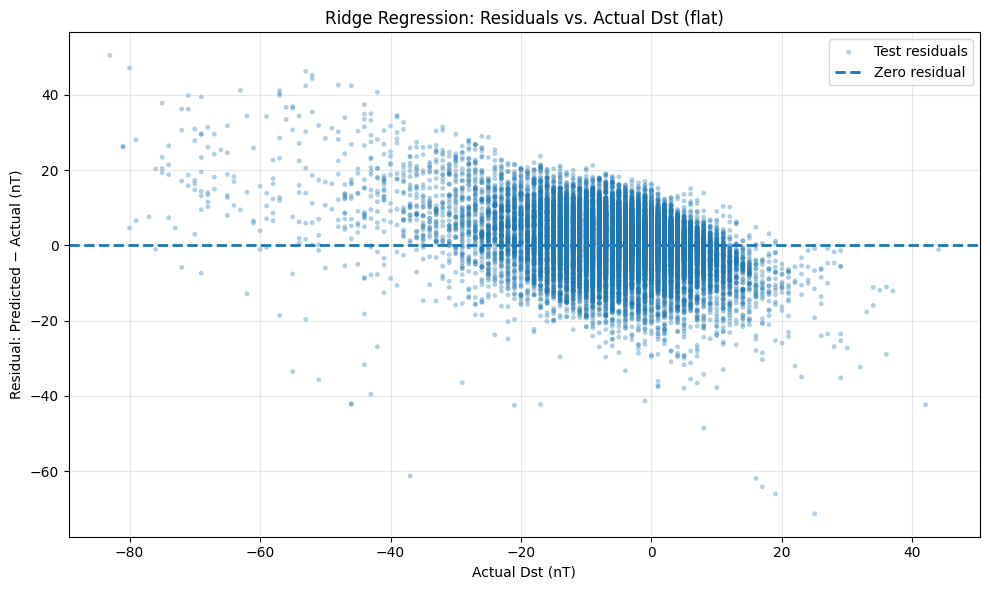

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_04_residuals_vs_actual_flat.png
Mean residual: 0.9259 nT
Residual standard deviation: 8.0345 nT



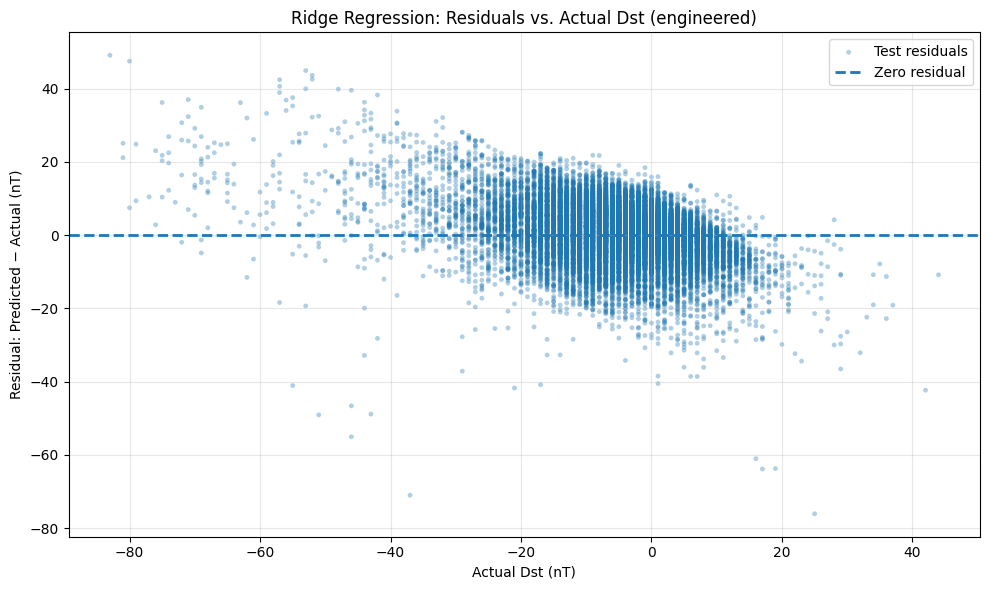

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures/ridge_04_residuals_vs_actual_engineered.png
Mean residual: 0.6112 nT
Residual standard deviation: 7.9786 nT

Cell 11 completed successfully.


In [11]:
# Cell 11: Ridge — Residuals vs. Actual Dst

def plot_residuals_vs_actual(y_true, y_pred, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        y_true,
        residuals,
        s=12,
        alpha=0.35,
        edgecolors="none",
        label="Test residuals",
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=2,
        label="Zero residual",
    )

    ax.set_title(
        f"Ridge Regression: Residuals vs. Actual Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Residual: Predicted − Actual (nT)")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"ridge_04_residuals_vs_actual_{representation}.png"
    )

    fig.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")
    print(f"Mean residual: {np.mean(residuals):.4f} nT")
    print(f"Residual standard deviation: {np.std(residuals):.4f} nT")


# Flat representation
plot_residuals_vs_actual(
    y_test_flat,
    flat_predictions,
    "flat",
)

print()

# Engineered representation
plot_residuals_vs_actual(
    y_test_eng,
    engineered_predictions,
    "engineered",
)

print("\nCell 11 completed successfully.")

In [12]:
# Cell 12: Save Ridge Results and Verify Artifacts

# ------------------------------------------------------------
# 1. Prepare output paths
# ------------------------------------------------------------

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

flat_model_path = RESULTS_PATH / "ridge_flat_model.joblib"
engineered_model_path = RESULTS_PATH / "ridge_engineered_model.joblib"

flat_scaler_path = RESULTS_PATH / "ridge_flat_scaler.joblib"
engineered_scaler_path = RESULTS_PATH / "ridge_engineered_scaler.joblib"

# ------------------------------------------------------------
# 2. Save selected models and fitted scalers
# ------------------------------------------------------------

joblib.dump(ridge_flat_model, flat_model_path)
joblib.dump(ridge_engineered_model, engineered_model_path)

joblib.dump(flat_scaler, flat_scaler_path)
joblib.dump(engineered_scaler, engineered_scaler_path)

print("Saved Ridge models and fitted scalers.")


# ------------------------------------------------------------
# 3. Calculate validation metrics
# ------------------------------------------------------------

flat_validation_metrics = evaluate_regression(
    y_val_flat,
    flat_validation_predictions,
)

engineered_validation_metrics = evaluate_regression(
    y_val_eng,
    engineered_validation_predictions,
)

validation_metrics_df = pd.DataFrame([
    {
        "Representation": "Flat",
        **flat_validation_metrics,
    },
    {
        "Representation": "Engineered",
        **engineered_validation_metrics,
    },
])

validation_metrics_path = (
    RESULTS_PATH / "ridge_validation_metrics.csv"
)

validation_metrics_df.to_csv(validation_metrics_path, index=False)

np.save(
    RESULTS_PATH / "ridge_flat_validation_predictions.npy",
    flat_validation_predictions,
)

np.save(
    RESULTS_PATH / "ridge_engineered_validation_predictions.npy",
    engineered_validation_predictions,
)

print("\nValidation metrics:")
display(validation_metrics_df.round(4))


# ------------------------------------------------------------
# 4. Save test metrics and predictions
# ------------------------------------------------------------

ridge_test_metrics_df = pd.DataFrame([
    {"Representation": "Flat", **flat_metrics},
    {"Representation": "Engineered", **engineered_metrics},
])

ridge_test_metrics_df.to_csv(
    RESULTS_PATH / "ridge_test_metrics.csv",
    index=False,
)

with open(RESULTS_PATH / "ridge_test_metrics.json", "w") as f:
    json.dump(
        {
            "flat": flat_metrics,
            "engineered": engineered_metrics,
        },
        f,
        indent=4,
        allow_nan=True,
    )

np.save(
    RESULTS_PATH / "ridge_flat_test_predictions.npy",
    flat_predictions,
)

np.save(
    RESULTS_PATH / "ridge_engineered_test_predictions.npy",
    engineered_predictions,
)

ridge_predictions_df = pd.DataFrame({
    "actual_dst": y_test_flat,
    "flat_predicted_dst": flat_predictions,
    "engineered_predicted_dst": engineered_predictions,
})

ridge_predictions_path = RESULTS_PATH / "ridge_test_predictions.csv"
ridge_predictions_df.to_csv(ridge_predictions_path, index=False)

print("\nHeld-out test metrics:")
display(ridge_test_metrics_df.round(4))


# ------------------------------------------------------------
# 5. Save alpha-search results
# ------------------------------------------------------------

flat_search_path = RESULTS_PATH / "ridge_flat_alpha_search.csv"
engineered_search_path = RESULTS_PATH / "ridge_engineered_alpha_search.csv"

flat_validation_results_df.to_csv(flat_search_path, index=False)
engineered_validation_results_df.to_csv(
    engineered_search_path,
    index=False,
)


# ------------------------------------------------------------
# 6. Save inference benchmark results
# ------------------------------------------------------------

inference_json_path = RESULTS_PATH / "ridge_inference_timing.json"
inference_csv_path = RESULTS_PATH / "ridge_inference_timing.csv"

with open(inference_json_path, "w") as f:
    json.dump(inference_results, f, indent=4)

inference_summary.to_csv(inference_csv_path, index=False)


# ------------------------------------------------------------
# 7. Record model, scaler, and combined artifact sizes
# ------------------------------------------------------------

model_information = {}

for representation, model_path, scaler_path, feature_count, selected_alpha, fit_time, tuning_time in [
    (
        "flat",
        flat_model_path,
        flat_scaler_path,
        X_train_flat.shape[1],
        best_flat_alpha,
        flat_training_duration,
        flat_tuning_duration,
    ),
    (
        "engineered",
        engineered_model_path,
        engineered_scaler_path,
        X_train_eng.shape[1],
        best_eng_alpha,
        engineered_training_duration,
        engineered_tuning_duration,
    ),
]:
    model_size_bytes = model_path.stat().st_size
    scaler_size_bytes = scaler_path.stat().st_size

    model_information[representation] = {
        "model_file": str(model_path),
        "scaler_file": str(scaler_path),
        "model_size_bytes": int(model_size_bytes),
        "model_size_mb": float(model_size_bytes / (1024 ** 2)),
        "scaler_size_bytes": int(scaler_size_bytes),
        "scaler_size_mb": float(scaler_size_bytes / (1024 ** 2)),
        "model_plus_scaler_size_mb": float(
            (model_size_bytes + scaler_size_bytes) / (1024 ** 2)
        ),
        "feature_count": int(feature_count),
        "coefficient_count": int(
            ridge_flat_model.coef_.size
            if representation == "flat"
            else ridge_engineered_model.coef_.size
        ),
        "selected_alpha": float(selected_alpha),
        "selected_model_fit_seconds": float(fit_time),
        "total_alpha_search_seconds": float(tuning_time),
    }

model_information_path = (
    RESULTS_PATH / "ridge_model_information.json"
)

with open(model_information_path, "w") as f:
    json.dump(model_information, f, indent=4)

print("\nModel and scaler information:")
display(pd.DataFrame([
    {"Representation": name.title(), **details}
    for name, details in model_information.items()
]).round(6))


# ------------------------------------------------------------
# 8. Save comprehensive experiment metrics
# ------------------------------------------------------------

complete_metrics = {
    "model_name": "Ridge Regression",
    "validation_metrics": {
        "flat": flat_validation_metrics,
        "engineered": engineered_validation_metrics,
    },
    "test_metrics": {
        "flat": flat_metrics,
        "engineered": engineered_metrics,
    },
    "model_information": model_information,
    "inference_benchmark": {
        "scope": (
            "Model prediction on already-scaled test features; "
            "StandardScaler transformation excluded."
        ),
        "flat": flat_inference,
        "engineered": engineered_inference,
    },
}

complete_metrics_path = RESULTS_PATH / "ridge_complete_metrics.json"

with open(complete_metrics_path, "w") as f:
    json.dump(complete_metrics, f, indent=4, allow_nan=True)


# ------------------------------------------------------------
# 9. Save experiment metadata
# ------------------------------------------------------------

run_metadata = {
    "model_name": MODEL_NAME,
    "model_family": "Linear Regression — Ridge",
    "random_state": int(RANDOM_STATE),
    "scikit_learn_version": sklearn.__version__,
    "python_version": platform.python_version(),
    "model_parameters": ridge_config,
    "selected_alpha": {
        "flat": float(best_flat_alpha),
        "engineered": float(best_eng_alpha),
    },
    "selection_metric": "Validation RMSE",
    "scaling": (
        "StandardScaler fitted on training data only, "
        "then applied to validation and test features."
    ),
    "dataset": {
        "training_samples": int(len(y_train_flat)),
        "validation_samples": int(len(y_val_flat)),
        "test_samples": int(len(y_test_flat)),
        "flat_feature_count": int(X_train_flat.shape[1]),
        "engineered_feature_count": int(X_train_eng.shape[1]),
        "target_splits_match": True,
    },
    "test_metrics": {
        "flat": flat_metrics,
        "engineered": engineered_metrics,
    },
    "inference_timing": {
        "warmup_runs": int(WARMUP_RUNS),
        "timed_repetitions": int(INFERENCE_REPEATS),
        "includes_scaling": False,
        "scope": "model.predict on pre-scaled test data",
    },
    "model_information": model_information,
}

metadata_path = RESULTS_PATH / "ridge_experiment_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(run_metadata, f, indent=4, allow_nan=True)

print(f"\nExperiment metadata saved: {metadata_path}")


# ------------------------------------------------------------
# 10. Verify expected result files and figures
# ------------------------------------------------------------

expected_result_files = [
    flat_model_path,
    engineered_model_path,
    flat_scaler_path,
    engineered_scaler_path,

    RESULTS_PATH / "ridge_configuration.json",
    flat_search_path,
    engineered_search_path,

    RESULTS_PATH / "ridge_flat_validation_predictions.npy",
    RESULTS_PATH / "ridge_engineered_validation_predictions.npy",
    validation_metrics_path,

    RESULTS_PATH / "ridge_flat_test_predictions.npy",
    RESULTS_PATH / "ridge_engineered_test_predictions.npy",
    ridge_predictions_path,
    RESULTS_PATH / "ridge_test_metrics.csv",
    RESULTS_PATH / "ridge_test_metrics.json",

    inference_json_path,
    inference_csv_path,
    model_information_path,
    complete_metrics_path,
    metadata_path,
]

expected_figure_files = [
    FIGURES_PATH / "ridge_01_actual_vs_predicted_flat.png",
    FIGURES_PATH / "ridge_01_actual_vs_predicted_engineered.png",
    FIGURES_PATH / "ridge_02_prediction_scatter_flat.png",
    FIGURES_PATH / "ridge_02_prediction_scatter_engineered.png",
    FIGURES_PATH / "ridge_03_rmse_by_dst_intensity_flat.png",
    FIGURES_PATH / "ridge_03_rmse_by_dst_intensity_engineered.png",
    FIGURES_PATH / "ridge_04_residuals_vs_actual_flat.png",
    FIGURES_PATH / "ridge_04_residuals_vs_actual_engineered.png",
]

verification_results = []

for artifact_path in expected_result_files + expected_figure_files:
    exists = artifact_path.exists()
    size_bytes = artifact_path.stat().st_size if exists else None

    verification_results.append({
        "Artifact": str(artifact_path.relative_to(RESULTS_PATH)),
        "Exists": exists,
        "Size (MB)": (
            round(size_bytes / (1024 ** 2), 6)
            if size_bytes is not None
            else None
        ),
    })

verification_df = pd.DataFrame(verification_results)

print("\nArtifact verification:")
display(verification_df)

missing_artifacts = verification_df.loc[
    ~verification_df["Exists"], "Artifact"
].tolist()

if missing_artifacts:
    print("\nWARNING: Expected artifacts are missing:")
    for artifact in missing_artifacts:
        print(f" - {artifact}")
else:
    print("\nAll expected Ridge artifacts are present.")

print(f"\nResults directory: {RESULTS_PATH}")
print(f"Figures directory: {FIGURES_PATH}")
print("\nCell 12 completed.")

Saved Ridge models and fitted scalers.

Validation metrics:


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,7.1495,9.4633,0.4847,0.7359,5.7853,0.4849,82.0307
1,Engineered,7.0512,9.3375,0.4983,0.7396,5.6111,0.4984,80.1054



Held-out test metrics:


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,6.1204,8.0877,0.4359,0.7209,4.9007,0.4433,71.3566
1,Engineered,6.0419,8.0020,0.4478,0.7236,4.8117,0.4510,76.0670



Model and scaler information:


,Representation,model_file,scaler_file,model_size_bytes,model_size_mb,scaler_size_bytes,scaler_size_mb,model_plus_scaler_size_mb,feature_count,coefficient_count,selected_alpha,selected_model_fit_seconds,total_alpha_search_seconds
0,Flat,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,4581,0.004369,24807,0.023658,0.028027,1008,1008,100.0,2.785478,113.862279
1,Engineered,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,997,0.000951,3303,0.003150,0.004101,112,112,100.0,1.221847,2.564385



Experiment metadata saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/ridge_experiment_metadata.json

Artifact verification:


,Artifact,Exists,Size (MB)
0,ridge_flat_model.joblib,True,0.004369
1,ridge_engineered_model.joblib,True,0.000951
2,ridge_flat_scaler.joblib,True,0.023658
3,ridge_engineered_scaler.joblib,True,0.003150
4,ridge_configuration.json,True,0.000419
5,ridge_flat_alpha_search.csv,True,0.000237
6,ridge_engineered_alpha_search.csv,True,0.000243
7,ridge_flat_validation_predictions.npy,True,0.080147
8,ridge_engineered_validation_predictions.npy,True,0.080147
9,ridge_validation_metrics.csv,True,0.000366



All expected Ridge artifacts are present.

Results directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge
Figures directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/Ridge/figures

Cell 12 completed.
